# Activity 7.06 – Visualizing the Impact of Education on Annual Salary and Weekly Working Hours



### 01: Use pandas to read the `age_salary_hours.csv` dataset located in the Datasets folder.



In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify
sns.set()

data = pd.read_csv('age_salary_hours.csv')
data.head()


,Age,Annual Salary,Weekly hours,Education
0,72,160000.0,40.0,Bachelor's degree or higher
1,72,100000.0,50.0,Bachelor's degree or higher
2,31,120000.0,40.0,Bachelor's degree or higher
3,28,45000.0,40.0,Bachelor's degree or higher
4,54,85000.0,40.0,Bachelor's degree or higher


### 02: Use a tree map to visualize the percentages for each education type.


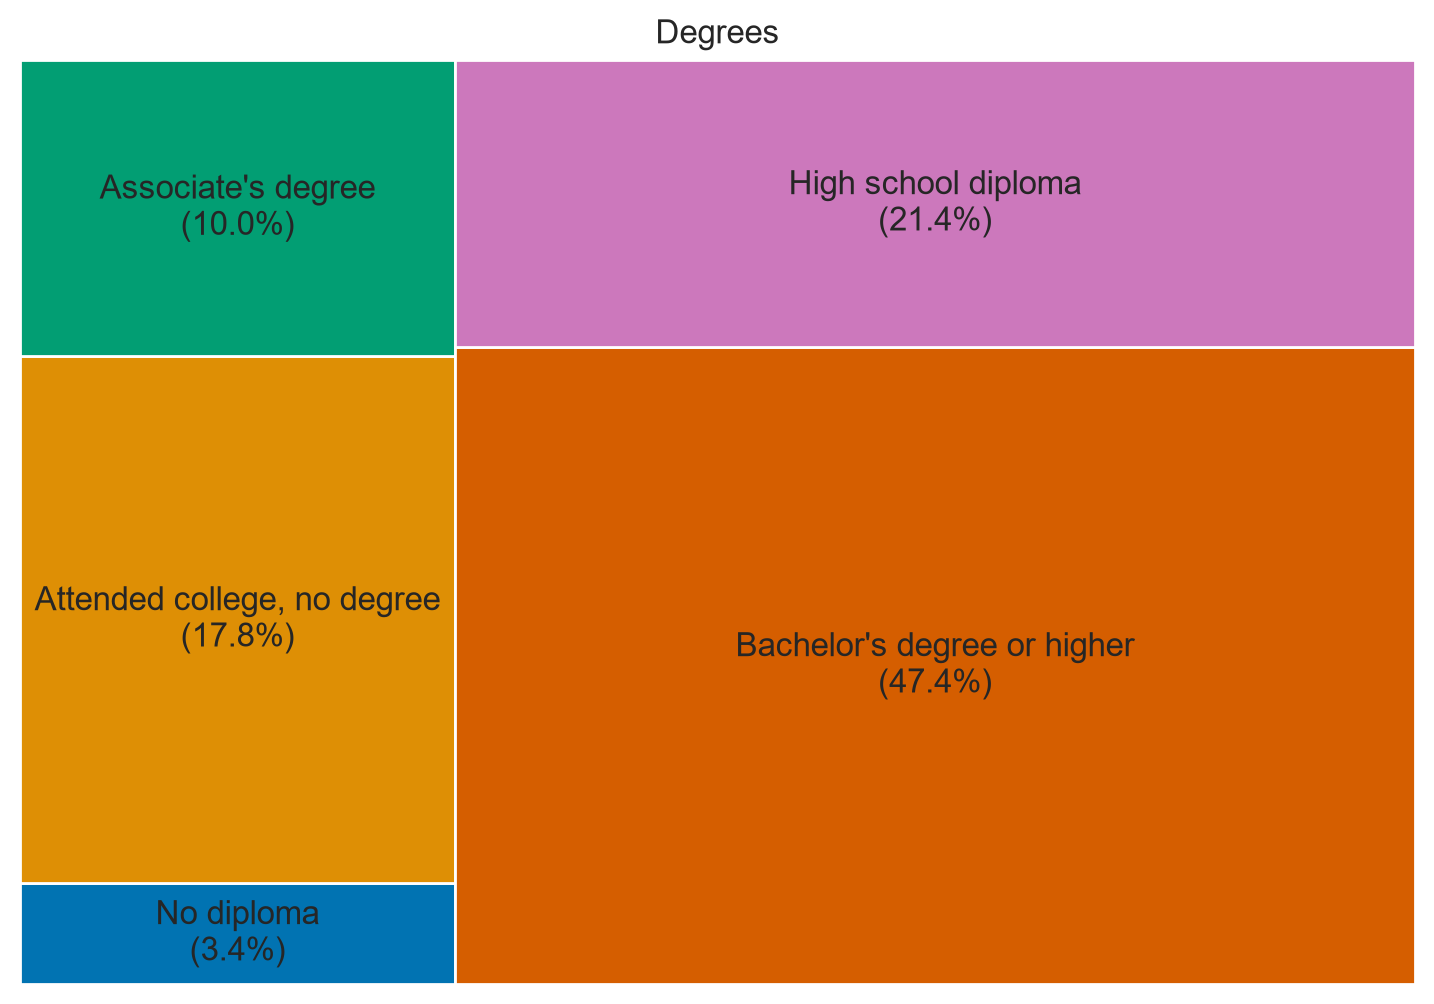

In [2]:
# Compute percentages from dataset
# (the iteration order is fixed to the textbook's set() order so that the
# layout of the tree map matches the expected output)
degrees = ['No diploma', 'Attended college, no degree', "Associate's degree",
           "Bachelor's degree or higher", 'High school diploma']
percentages = []
for degree in degrees:
    percentages.append(data[data['Education'] == degree].shape[0])
percentages = np.array(percentages)
percentages = ((percentages / percentages.sum()) * 100)

# Create labels for tree map
labels = [degree + '\n({0:.1f}%)'.format(percentage)
          for degree, percentage in zip(degrees, percentages)]

# Create figure
plt.figure(figsize=(9, 6), dpi=200)
squarify.plot(percentages, label=labels,
              color=sns.color_palette('colorblind', len(degrees)))
plt.axis('off')
# Add title
plt.title('Degrees')
# Show plot
plt.show()


### 03: Create a subplot with two rows to visualize two violin plots for the annual salary and weekly working hours, respectively. Compare in each case to what extent education has an impact. To exclude pensioners, only consider people younger than 65. Use a colormap that is suitable for colorblind people. `subplots()` can be used in combination with Seaborn's plot, by simply passing the `ax` argument with the respective axes.


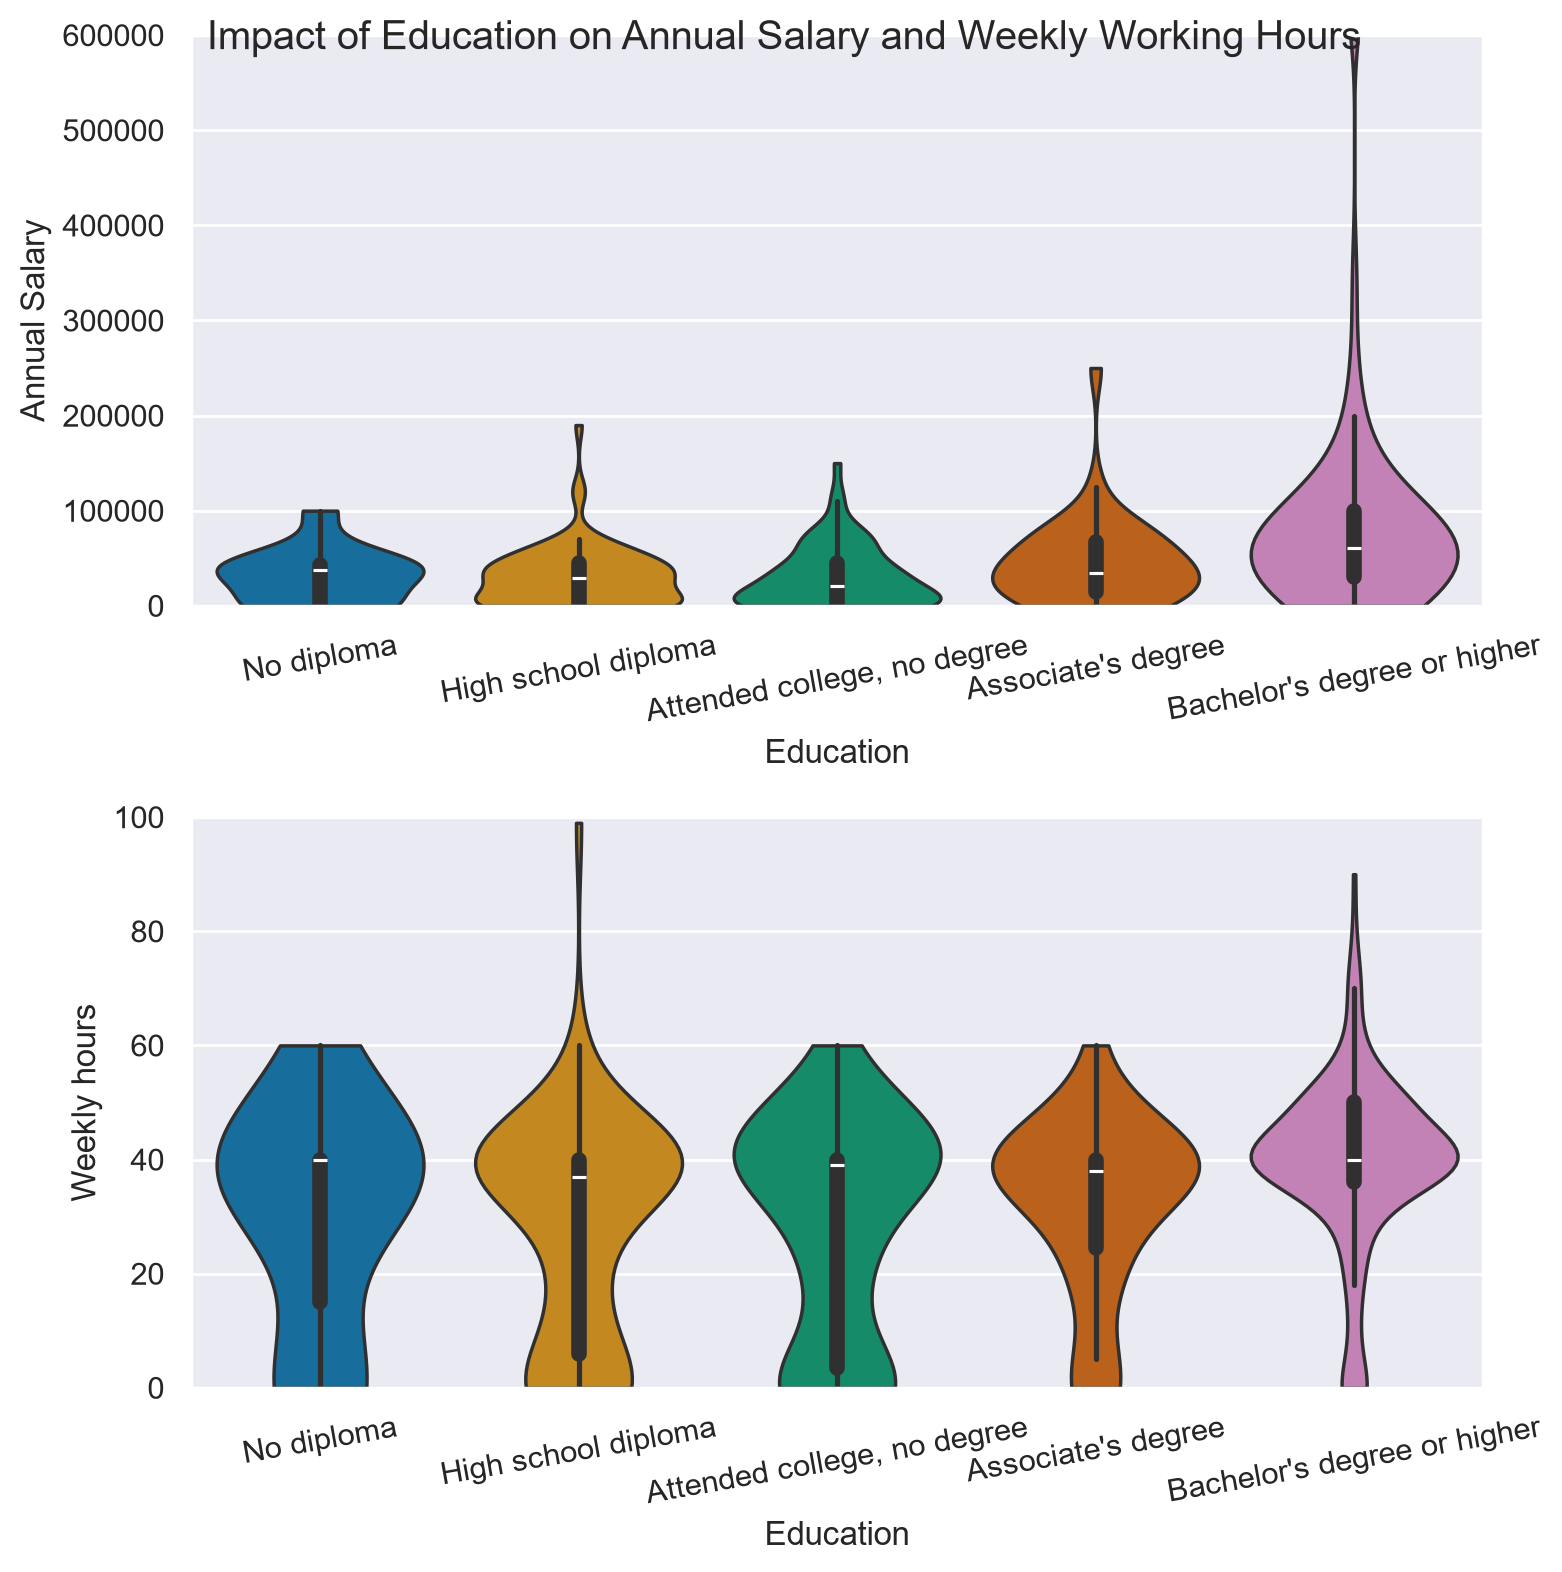

In [3]:
# Order the education levels from lowest to highest
ordered_degrees = sorted(list(degrees))
ordered_degrees = [ordered_degrees[4], ordered_degrees[3], ordered_degrees[1],
                   ordered_degrees[0], ordered_degrees[2]]

# Exclude pensioners: only consider people younger than 65
data = data.loc[data['Age'] < 65]

# Set color palette to colorblind
sns.set_palette('colorblind')
violin_colors = sns.color_palette('colorblind', len(ordered_degrees))

# Create subplot with two rows
fig, ax = plt.subplots(2, 1, dpi=200, figsize=(8, 8))
sns.violinplot(x='Education', y='Annual Salary', data=data, cut=0,
               order=ordered_degrees, hue='Education', hue_order=ordered_degrees,
               palette=violin_colors, legend=False, dodge=False, ax=ax[0])
plt.setp(ax[0].get_xticklabels(), rotation=10)
ax[0].set_ylim(0, 600000)
sns.violinplot(x='Education', y='Weekly hours', data=data, cut=0,
               order=ordered_degrees, hue='Education', hue_order=ordered_degrees,
               palette=violin_colors, legend=False, dodge=False, ax=ax[1])
plt.setp(ax[1].get_xticklabels(), rotation=10)
ax[1].set_ylim(0, 100)
plt.tight_layout()
# Add title
fig.suptitle('Impact of Education on Annual Salary and Weekly Working Hours')
# Show figure
plt.show()
